# Mini-Challenge DEL: Hyperparameter Tuning und Model Evaluation

In [ ]:
# Standard Library
import itertools
import json
import os
from pathlib import Path
import sys

# Third-Party Libraries
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate
from skorch import NeuralNetClassifier
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import wandb



In [7]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

In [ ]:
from src.hyp_tests.common import build_paired_summary

## Erste Etappe: Daten Kennenlernen, Aufbau Modellierung & Basismodell
In dieser Phase legst du das Fundament für dein Deep Learning Projekt. Ziel ist es, die Daten zu verstehen, eine stabile Trainings-Pipeline aufzubauen und die Performance eines einfachen Basismodells als Referenzwert zu ermitteln.

### 1. Vorbereitung der Daten

* a) Explorative Analyse: Führe eine kurze Analyse der Features durch. Untersuche dabei insbesondere:
* Den Vergleich der Klassen pro Feature.
   * Die Balanciertheit der Klassen (Class Balance).
* b) Preprocessing: Implementiere geeignete Vorverarbeitungsschritte (z. B. Normalisierung oder Standardisierung der Daten).


In [8]:
# Laden des svhn
def load_svhn_data(batch_size=64):
    transform = transforms.Compose([
        transforms.ToTensor(),        
    ])

    train_dataset = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
    test_dataset = datasets.SVHN(root='../data', split='test', download=True, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader

train_loader, test_loader = load_svhn_data()


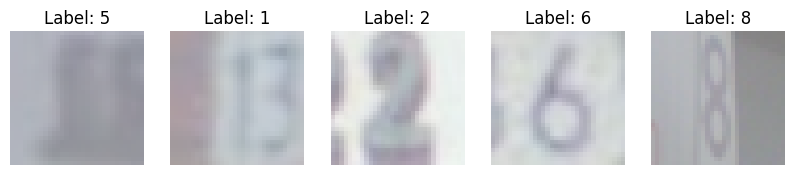

In [9]:
# EDA: Visualize some samples from the dataset
data_iter = iter(train_loader)
num_samples_to_show = 5

images, labels = next(data_iter)

plt.figure(figsize=(10, 2))
for i in range(num_samples_to_show):
    plt.subplot(1, num_samples_to_show, i + 1)
    plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)) * 0.5 + 0.5)
    plt.title(f'Label: {labels[i].item()}')
    plt.axis('off')
plt.show()



=== Train: Klassenverteilung ===
 Klasse  Anzahl  Anteil_%
      0    4948      6.75
      1   13861     18.92
      2   10585     14.45
      3    8497     11.60
      4    7458     10.18
      5    6882      9.39
      6    5727      7.82
      7    5595      7.64
      8    5045      6.89
      9    4659      6.36
Imbalance-Ratio (max/min): 2.98

=== Test: Klassenverteilung ===
 Klasse  Anzahl  Anteil_%
      0    1744      6.70
      1    5099     19.59
      2    4149     15.94
      3    2882     11.07
      4    2523      9.69
      5    2384      9.16
      6    1977      7.59
      7    2019      7.76
      8    1660      6.38
      9    1595      6.13
Imbalance-Ratio (max/min): 3.20

=== Train: Durchschnittliche Feature-Werte je Klasse ===
        Mean_R  Mean_G  Mean_B  Mean_Intensity
Klasse                                        
0       0.4432  0.4499  0.4772          0.4568
1       0.4370  0.4421  0.4711          0.4501
2       0.4420  0.4473  0.4752          0.4548
3   

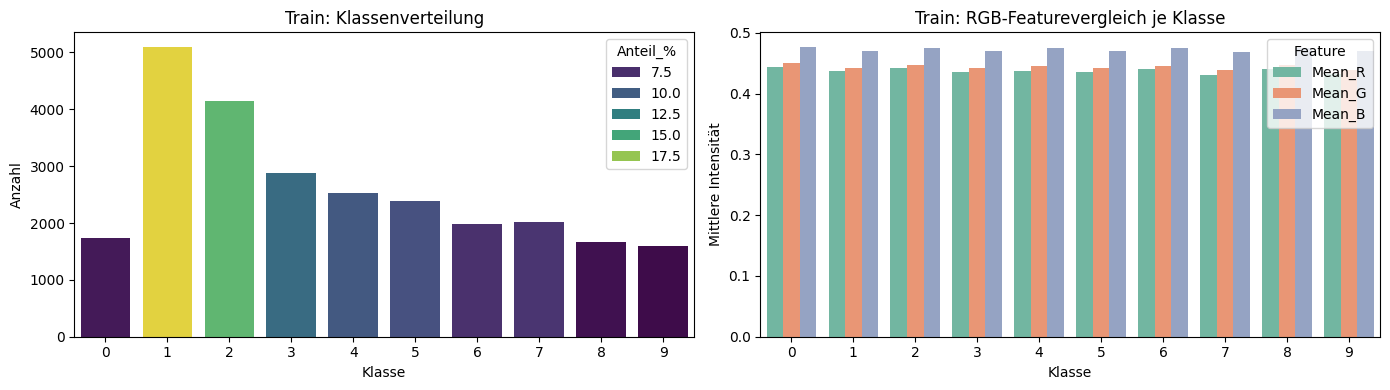


=== Test: Durchschnittliche Feature-Werte je Klasse ===
        Mean_R  Mean_G  Mean_B  Mean_Intensity
Klasse                                        
0       0.4579  0.4578  0.4757          0.4638
1       0.4518  0.4501  0.4653          0.4557
2       0.4483  0.4494  0.4664          0.4547
3       0.4475  0.4496  0.4664          0.4545
4       0.4517  0.4528  0.4702          0.4582
5       0.4530  0.4531  0.4695          0.4585
6       0.4591  0.4591  0.4743          0.4641
7       0.4515  0.4519  0.4688          0.4574
8       0.4582  0.4561  0.4724          0.4623
9       0.4553  0.4551  0.4721          0.4609


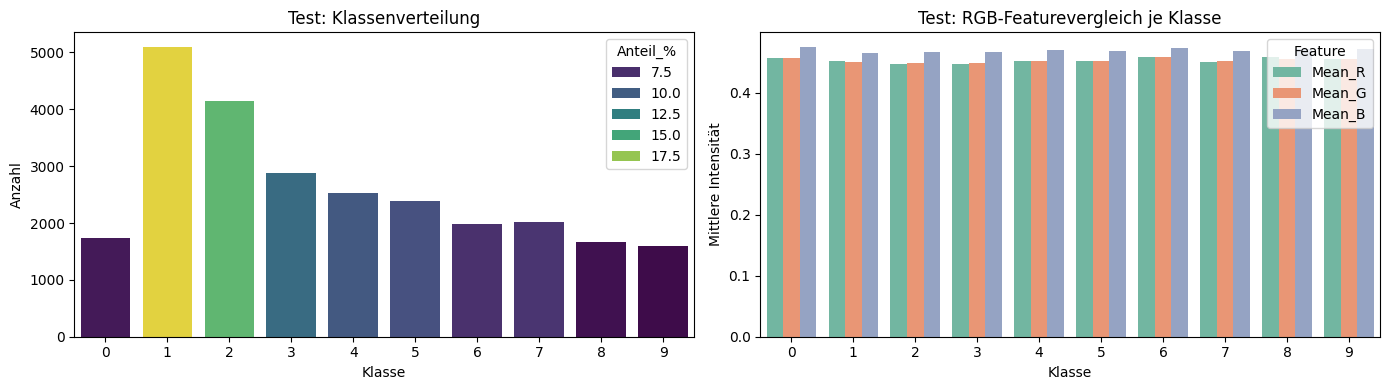

In [10]:
# EDA: Klassen-Balanciertheit + Featurevergleich (RGB-Intensitäten je Klasse)

def prepare_labels(dataset):
    labels = np.array(dataset.labels)
    labels = np.where(labels == 10, 0, labels)
    return labels

def class_dist(labels, split_name="Train"):
    # Klassenverteilung
    class_counts = pd.Series(labels).value_counts().sort_index()
    class_pct = (class_counts / class_counts.sum() * 100).round(2)

    dist_df = pd.DataFrame({
        "Klasse": class_counts.index,
        "Anzahl": class_counts.values,
        "Anteil_%": class_pct.values
    })

    return dist_df, class_counts



def feature_comp(ds, labels, split_name="Train"):
    images = ds.data.astype(np.float32) / 255.0  # (N, C, H, W)

    # Featurevergleich: mittlere RGB-Intensitäten je Bild und Klasse
    mean_r = images[:, 0].mean(axis=(1, 2))
    mean_g = images[:, 1].mean(axis=(1, 2))
    mean_b = images[:, 2].mean(axis=(1, 2))
    mean_intensity = images.mean(axis=(1, 2, 3))

    feat_df = pd.DataFrame({
        "Klasse": labels,
        "Mean_R": mean_r,
        "Mean_G": mean_g,
        "Mean_B": mean_b,
        "Mean_Intensity": mean_intensity
    })

    class_feat = feat_df.groupby("Klasse")[["Mean_R", "Mean_G", "Mean_B", "Mean_Intensity"]].mean()
    print(f"\n=== {split_name}: Durchschnittliche Feature-Werte je Klasse ===")
    print(class_feat.round(4))

    # Visualisierungen
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.barplot(data=dist_df, x="Klasse", y="Anzahl", ax=axes[0], palette="viridis", hue="Anteil_%", dodge=False)
    axes[0].set_title(f"{split_name}: Klassenverteilung")
    axes[0].set_xlabel("Klasse")
    axes[0].set_ylabel("Anzahl")

    class_feat_plot = class_feat.reset_index().melt(
        id_vars="Klasse",
        value_vars=["Mean_R", "Mean_G", "Mean_B"],
        var_name="Feature",
        value_name="Mittelwert"
    )
    sns.barplot(data=class_feat_plot, x="Klasse", y="Mittelwert", hue="Feature", ax=axes[1], palette="Set2",)
    axes[1].set_title(f"{split_name}: RGB-Featurevergleich je Klasse")
    axes[1].set_xlabel("Klasse")
    axes[1].set_ylabel("Mittlere Intensität")
    axes[1].legend(title="Feature")

    plt.tight_layout()
    plt.show()


# EDA für Train und Test
train_labels = prepare_labels(train_loader.dataset)
test_labels = prepare_labels(test_loader.dataset)

for split_name, current_labels in [("Train", train_labels), ("Test", test_labels)]:
    dist_df, class_counts = class_dist(current_labels, split_name=split_name) 
    
    print(f"\n=== {split_name}: Klassenverteilung ===")
    print(dist_df.to_string(index=False))
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Imbalance-Ratio (max/min): {imbalance_ratio:.2f}")

feature_comp(train_loader.dataset, train_labels, split_name="Train")
feature_comp(test_loader.dataset, test_labels, split_name="Test")


In [11]:
# Preprocessing der Daten
# calculate mean and std for normalization for each channel
def get_stats(loader):
    sum_, squared_sum, batches = 0, 0, 0
    
    for images, _ in loader:
        # images: [batch_size, 3, 32, 32]
        sum_ += torch.mean(images, dim=[0, 2, 3])
        squared_sum += torch.mean(images**2, dim=[0, 2, 3])
        batches += 1
        
    mean = sum_ / batches
    std = (squared_sum / batches - mean**2)**0.5
    return mean, std

# Berechnung
mean, std = get_stats(train_loader)
print(f"Mean: {mean}")
print(f"Std: {std}")


Mean: tensor([0.4377, 0.4438, 0.4728])
Std: tensor([0.1980, 0.2010, 0.1970])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.606148..2.799971].


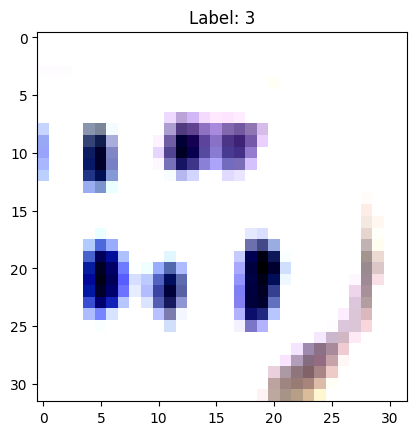

In [12]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_set = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
test_set = datasets.SVHN(root='../data', split='test', download=True, transform=transform)
    
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

# 2. Visualisieren
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Normalisiertes Bild Anzeigen:
plt.imshow(images[0].permute(1, 2, 0)) # Permute für (H, W, C)
plt.title(f"Label: {labels[0]}")
plt.show()

### 2. Evaluation

* Lege die Metriken fest, mit denen die Performance der Modelle gemessen werden soll (z. B. Accuracy, F1-Score, Loss).



### Metriken

Da der vorliegende Datensatz eine starke Klassenimbalance aufweist, ist die Accuracy als alleinige Metrik nicht aussagekräftig. Um die Modellleistung über alle Kategorien hinweg objektiv zu bewerten, fokussiere ich mich stattdessen auf den F1-Score sowie Precision und Recall.
Da es sich um ein Multiclass-Problem handelt, wird der CrossEntropyLoss als Verlustfunktion verwendet. Um sicherzustellen, dass auch minderbesetzte Klassen angemessen berücksichtigt werden, kommen bei der Evaluation die Macro-Averages (Macro F1, Macro Precision und Macro Recall) zum Einsatz. 


### 3. Implementierung der Basisfunktionalität

a) Training & Evaluation: Erstelle Funktionen oder Klassen für den standardisierten Trainings- und Evaluationsprozess.

b) MLOps Integration: Binde eine Plattform wie Weights & Biases (W&B) ein, um Experimente zu loggen.

c) Basismodell: Implementiere das vereinbarte einfache Basismodell.

d) Overfitting Test: Trainiere das Modell mit einem einzelnen Sample oder einem einzigen Batch. Wenn das Modell verlustfrei auf diesem Batch lernt, ist die Basisfunktionalität korrekt implementiert.


#### Design

1. **Konfiguration über `RunConfig`**
    - Zentrale Parameter (z. B. `learning_rate`, `batch_size`, `epochs`, `device`) werden in `baseline_config` gebündelt.

2. **Baseline-Training über `run_baseline(...)`**

3. **Experiment-Tracking mit Weights & Biases**
    - Aktiviert über `use_wandb=True` in der Config.
    - Projektname: `DEL`, Run-Name: `baseline-example`.

4. **Auswertung über `WandbRuns`**
    - lädt Runs aus W&B:
    ```python
    wandb_runs = WandbRuns(project="DEL")
    overview_df = wandb_runs.runs_overview(top_k=10)
    ```
    - Zusätzlich vergleichst du Metriken (z. B. `val/loss`) direkt zwischen Runs.


#### Struktur

```text
src/
├── training.py
│   ├── RunConfig            # Konfigurationsdataclass für Training
│   └── run_baseline(...)    # Führt Baseline-Training + Evaluation aus
├── wandb_tools.py
│   └── WandbRuns            # Laden, Filtern, Vergleichen von W&B-Runs
├── model.py            # Modellarchitekturen
└── metrics.py           # F1, Precision, Recall (Macro)
```

In [13]:
# Overfitting-Test: Kann das Basismodell einen einzelnen Batch auswendig lernen?
from torch.utils.data import DataLoader, TensorDataset
from src.training import FitConfig, run_baseline, RunConfig

# single batch aus dem train_loader extrahieren
batch_images, batch_labels = next(iter(train_loader))
overfit_dataset = TensorDataset(batch_images.clone(), batch_labels.clone())
overfit_loader = DataLoader(overfit_dataset, batch_size=len(overfit_dataset), shuffle=False)

overfit_config = RunConfig(
    learning_rate=1e-2,
    batch_size=len(overfit_dataset),
    epochs=1000,
    use_wandb=False,
    wandb_project="DEL",
    run_name="overfit-single-batch",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_seed=42,
    tags=["overfit-check"],
)

overfit_result = run_baseline(
    config=overfit_config,
    fit_config=FitConfig(epochs=1000),
    train_loader=overfit_loader,
)


In [14]:
history = overfit_result["history"]
print(f"Final train accuracy: {history['train_accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history['val_accuracy'][-1]:.4f}")
print(f"Final train loss: {history['train_loss'][-1]:.4f}")
print(f"Final val loss: {history['val_loss'][-1]:.4f}")

Final train accuracy: 1.0000
Final val accuracy: 0.0000
Final train loss: 0.0015
Final val loss: 8.4580


In [15]:
overfit_result["history"].keys()

dict_keys(['train_accuracy', 'train_macro_precision', 'train_macro_recall', 'train_macro_f1', 'train_loss', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_loss'])

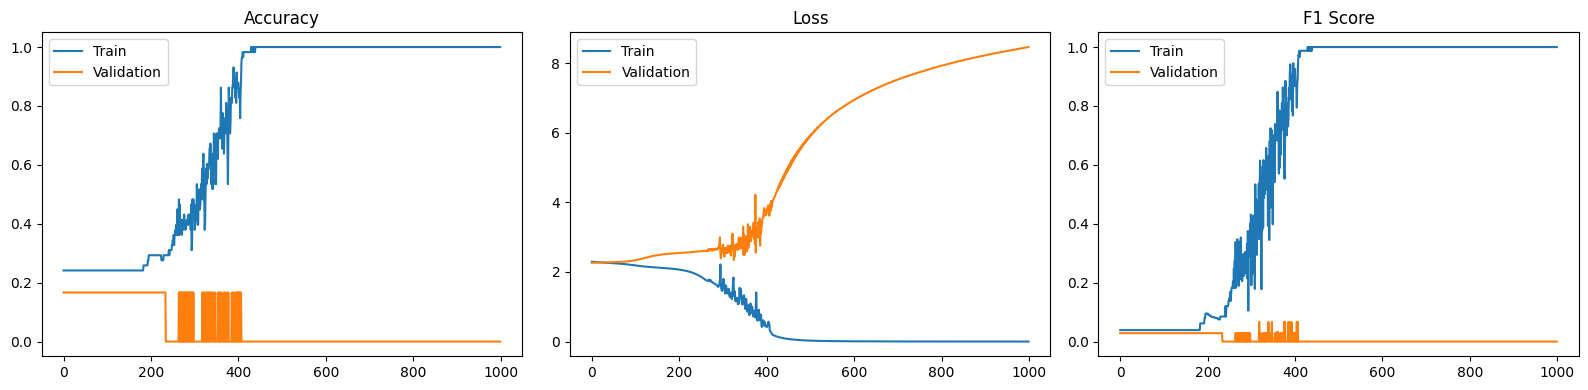

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(pd.DataFrame(history["train_accuracy"]))
axes[0].plot(pd.DataFrame(history["val_accuracy"]))
axes[0].set_title("Accuracy")
axes[0].legend(["Train", "Validation"])

axes[1].plot(pd.DataFrame(history["train_loss"]))
axes[1].plot(pd.DataFrame(history["val_loss"]))
axes[1].set_title("Loss")
axes[1].legend(["Train", "Validation"])

axes[2].plot(pd.DataFrame(history["train_macro_f1"]))
axes[2].plot(pd.DataFrame(history["val_macro_f1"]))
axes[2].set_title("F1 Score")
axes[2].legend(["Train", "Validation"])

plt.tight_layout()
plt.show(fig)

### 4. Training des Basismodells

In diesem Abschnitt wird die geforderte Basis-Konfiguration umgesetzt:
- SGD ohne Momentum
- keine Regularisierung (weight decay = 0)
- keine Batch-Normalization
- manuelles Tuning von Lernrate und Batchsize (kein Auto-Search)
- Schätzung des statistischen Fehlers mit Cross-Validation

#### 4a) Training mit SGD ohne Momentum/Regularisierung/BatchNorm (alle Trainingsdaten)

Es wird auf dem gesamten Trainingsset trainiert. Zur Lernkurven-Überwachung dient das offizielle Testset als Evaluationsset pro Epoche.

In [34]:
from src.training import run_baseline, RunConfig, FitConfig
from src.wandb_tools import WandbRuns

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
wandb_runs = WandbRuns(project="DEL", entity="lukas-breiter-fachhochschule-nordwestschweiz-fhnw")


In [18]:
baseline_config = RunConfig(
    learning_rate=1e-2,
    batch_size=64,
    epochs=30,
    use_wandb=True,
    val_fraction=0.1,
    wandb_project="DEL",
    run_name="Baseline-Example",
    tags=["baseline"],
    device=DEVICE,
    random_seed=SEED,
    num_workers=4,
    pin_memory=torch.cuda.is_available(),
)
 
baseline_result = run_baseline(
    config=baseline_config,
    fit_config=FitConfig(epochs=baseline_config.epochs),
    train_loader=train_loader,
)

wandb: Currently logged in as: lukas-breiter (lukas-breiter-fachhochschule-nordwestschweiz-fhnw) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
train/accuracy,▁▂▅▇▇▇▇▇▇▇████████████████████
train/loss,██▄▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/macro_f1,▁▂▆▇▇▇▇▇▇█████████████████████
train/macro_precision,▁▃▆▇▇▇▇▇▇█████████████████████
train/macro_recall,▁▂▅▇▇▇▇▇▇█████████████████████
val/accuracy,▁▄▆▇▆███████████▇█████████████
val/loss,█▆▃▂▃▁▁▁▁▁▁▁▁▁▁▁▃▂▂▂▂▂▂▂▂▂▂▂▂▃
val/macro_f1,▁▄▆▇▇███████████▇█████████████
val/macro_precision,▁▅▇█▇█████████████████████████
+1,...


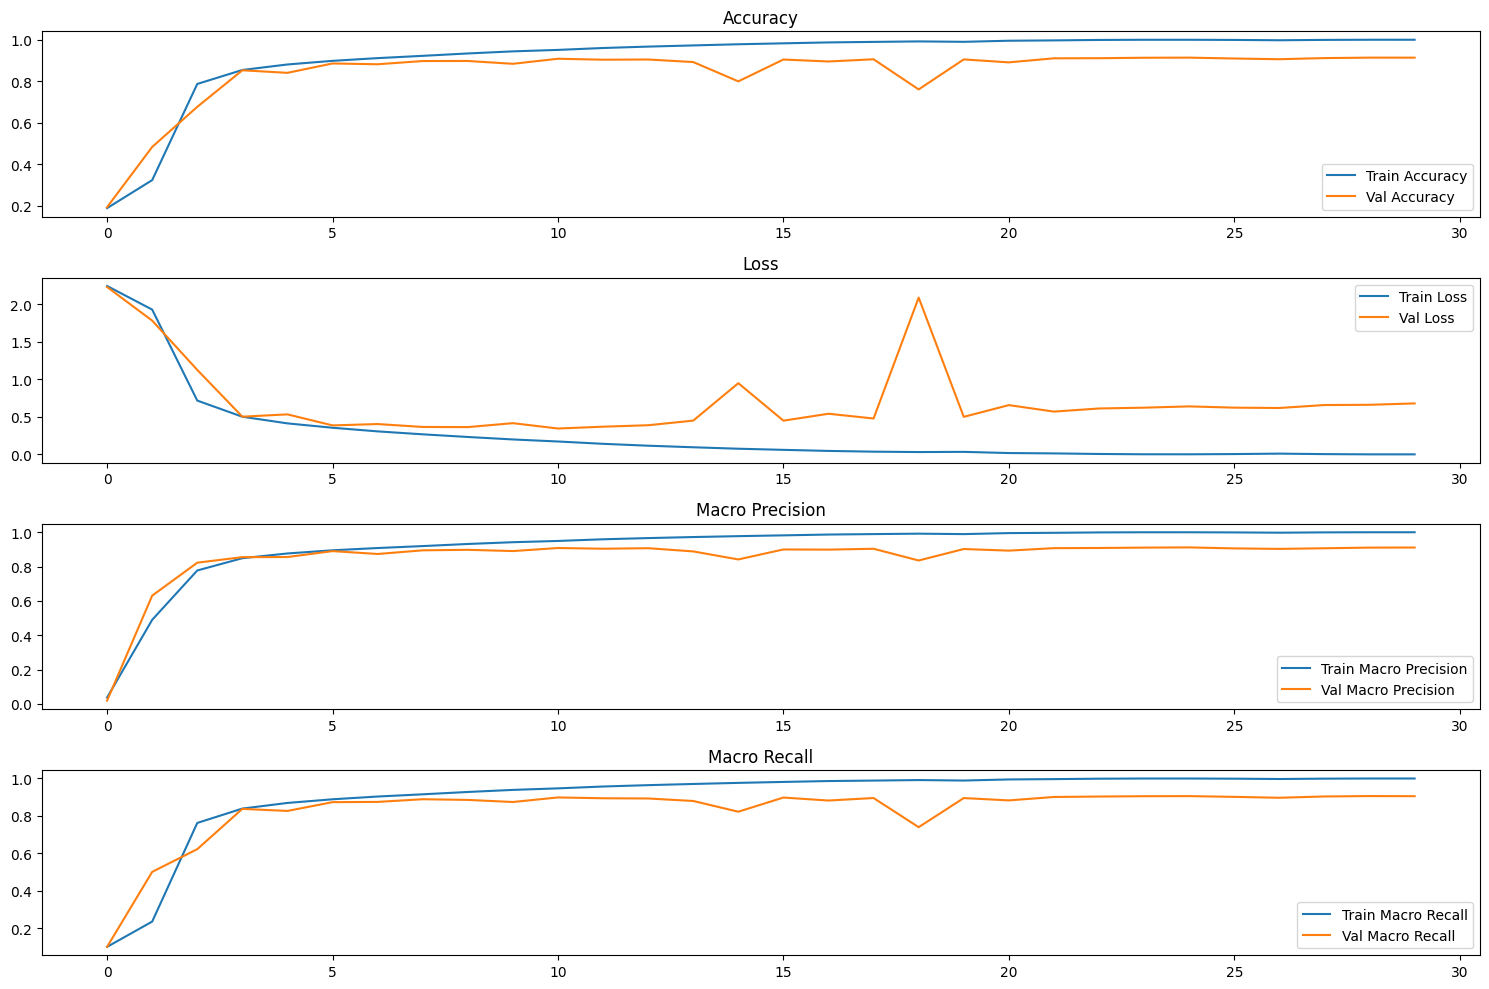

In [20]:
baseline_example_hist = wandb_runs.history(
    run_path="lukas-breiter-fachhochschule-nordwestschweiz-fhnw/DEL/p1bq9mdy",
    keys=["val/macro_recall", "val/macro_precision", "val/macro_f1", "val/loss", "val/accuracy", "train/accuracy", "train/loss", "train/macro_recall", "train/macro_precision", "train/macro_f1"],
)

fig, axes = plt.subplots(4, 1, figsize=(15, 10))
axes[0].plot(baseline_example_hist["train/accuracy"], label="Train Accuracy")
axes[0].plot(baseline_example_hist["val/accuracy"], label="Val Accuracy")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(baseline_example_hist["train/loss"], label="Train Loss")
axes[1].plot(baseline_example_hist["val/loss"], label="Val Loss")
axes[1].set_title("Loss")
axes[1].legend()

axes[2].plot(baseline_example_hist["train/macro_precision"], label="Train Macro Precision")
axes[2].plot(baseline_example_hist["val/macro_precision"], label="Val Macro Precision")
axes[2].set_title("Macro Precision")
axes[2].legend()

axes[3].plot(baseline_example_hist["train/macro_recall"], label="Train Macro Recall")
axes[3].plot(baseline_example_hist["val/macro_recall"], label="Val Macro Recall")
axes[3].set_title("Macro Recall")
axes[3].legend()

plt.tight_layout()
plt.show()


In [21]:
print("Finale Werte (4a):")
baseline_example_hist = baseline_example_hist.sort_values("_step")
print(f"val_loss: {baseline_example_hist['val/loss'].iloc[-1]:.4f}")
print(f"val_accuracy: {baseline_example_hist['val/accuracy'].iloc[-1]:.4f}")
print(f"val_macro_precision: {baseline_example_hist['val/macro_precision'].iloc[-1]:.4f}")
print(f"val_macro_recall: {baseline_example_hist['val/macro_recall'].iloc[-1]:.4f}")
print(f"val_macro_f1: {baseline_example_hist['val/macro_f1'].iloc[-1]:.4f}")

Finale Werte (4a):
val_loss: 0.6794
val_accuracy: 0.9136
val_macro_precision: 0.9110
val_macro_recall: 0.9054
val_macro_f1: 0.9079


#### 4b) Manuelles Tuning von Lernrate und Batchsize (keine automatische Suche)

Für das Tuning wird ausschließlich die etablierte Funktion `run_baseline(...)` aus `src.training` verwendet.
Es wird ein kleiner manueller Grid getestet (kein Bayes, kein AutoML).

In [22]:
learning_rates = [5e-2, 1e-2, 5e-3]
batch_sizes = [32, 64, 128]
tuning_epochs =  30

tuning_runs = []
histories = {}

for lr, bs in itertools.product(learning_rates, batch_sizes):
    run_name = f"Baseline_Tuning-lr{lr}-bs{bs}"
    train_loader_cfg,_ = load_svhn_data(batch_size=bs)

    result = run_baseline(
        config=RunConfig(
            learning_rate=lr,
            batch_size=bs,
            epochs=tuning_epochs,
            val_fraction=0.1,
            use_wandb=True,
            wandb_project="DEL",
            run_name=run_name,
            tags=["baseline"],
            device=DEVICE,
            random_seed=SEED,
            num_workers=4,
            pin_memory=torch.cuda.is_available(),
        ),
        fit_config=FitConfig(epochs=tuning_epochs),
        train_loader=train_loader_cfg,
    )

    h = result["history"]
    histories[(lr, bs)] = h
    tuning_runs.append(
        {
            "learning_rate": lr,
            "batch_size": bs,
            "val_loss": h["val_loss"][-1],
            "val_accuracy": h["val_accuracy"][-1],
            "val_macro_precision": h["val_macro_precision"][-1],
            "val_macro_recall": h["val_macro_recall"][-1],
            "val_macro_f1": h["val_macro_f1"][-1],
        }
    )

wandb: ERROR Problem finishing run


HandleAbandonedError: 

In [35]:
tuning_runs_list = pd.DataFrame(wandb_runs.runs_overview())

In [36]:
tuning_runs_list

,id,name,state,created_at,val_accuracy,val_macro_f1,val_loss
0,0tql7sdt,Baseline_Tuning-lr0.005-bs128,finished,2026-04-02T16:17:50Z,0.770648,0.759166,0.753209
1,c626pze0,Baseline_Tuning-lr0.005-bs64,finished,2026-04-02T16:14:01Z,0.866894,0.861246,0.500818
2,o7vr260n,Baseline_Tuning-lr0.005-bs32,finished,2026-04-02T16:08:53Z,0.892014,0.884271,0.571851
3,wjvhdz4i,Baseline_Tuning-lr0.01-bs128,finished,2026-04-02T16:05:37Z,0.788532,0.786637,0.858603
4,nu21hphj,Baseline_Tuning-lr0.01-bs64,finished,2026-04-02T16:01:49Z,0.904710,0.898534,0.622018
5,pa5vlhr9,Baseline_Tuning-lr0.01-bs32,finished,2026-04-02T15:56:42Z,0.915358,0.910722,0.680779
6,6um2rgz2,Baseline_Tuning-lr0.05-bs128,finished,2026-04-02T15:53:14Z,0.916587,0.911880,0.688774
7,ert1c6aw,Baseline_Tuning-lr0.05-bs64,finished,2026-04-02T15:49:26Z,0.921229,0.916715,0.725566
8,my5g11x6,Baseline_Tuning-lr0.05-bs32,finished,2026-04-02T15:44:10Z,0.922594,0.917813,0.710240
9,p1bq9mdy,Baseline-Example,finished,2026-04-02T15:38:21Z,0.913584,0.907916,0.679395


In [37]:
tuning_results = []
filtered_ids = set(tuning_runs_list["id"]) - {"p1bq9mdy"}

for run_id in filtered_ids:
    baseline_example_hist = wandb_runs.history(
        run_path=f"lukas-breiter-fachhochschule-nordwestschweiz-fhnw/DEL/{run_id}",
        keys=["val/macro_recall", "val/macro_precision", "val/macro_f1", "val/loss", "val/accuracy", 
              "train/accuracy", "train/loss", "train/macro_recall", "train/macro_precision", "train/macro_f1"
              ],
    )

    hist_df = baseline_example_hist.copy()
    hist_df["run_id"] = run_id
    hist_df["learning_rate"] = tuning_runs_list.loc[tuning_runs_list["id"] == run_id, "name"].values[0].split("-")[1]
    hist_df["batch_size"] = tuning_runs_list.loc[tuning_runs_list["id"] == run_id, "name"].values[0].split("-")[2]
    tuning_results.append(hist_df)

tuning_result_df = pd.concat(tuning_results, ignore_index=True)
tuning_result_df.head()

wandb: WARNING A graphql request initiated by the public wandb API timed out (timeout=19 sec). Create a new API with an integer timeout larger than 19, e.g., `api = wandb.Api(timeout=29)` to increase the graphql timeout.
wandb: WARNING A graphql request initiated by the public wandb API timed out (timeout=19 sec). Create a new API with an integer timeout larger than 19, e.g., `api = wandb.Api(timeout=29)` to increase the graphql timeout.


KeyboardInterrupt: 

In [32]:
# Build one-row-per-run summary from tuning_result_df (last logged epoch per run)
tuning_df = (
    tuning_result_df
    .sort_values(["run_id", "_step"])
    .groupby("run_id", as_index=False)
    .tail(1)
    .loc[:, [
        "run_id",
        "learning_rate",
        "batch_size",
        "val/loss",
        "val/accuracy",
        "val/macro_precision",
        "val/macro_recall",
        "val/macro_f1",
    ]]
    .rename(columns={
        "val/loss": "val_loss",
        "val/accuracy": "val_accuracy",
        "val/macro_precision": "val_macro_precision",
        "val/macro_recall": "val_macro_recall",
        "val/macro_f1": "val_macro_f1",
    })
    .copy()
)

# Parse lr/bs strings like "lr0.01", "bs64"
tuning_df["learning_rate"] = tuning_df["learning_rate"].str.replace("lr", "", regex=False).astype(float)
tuning_df["batch_size"] = tuning_df["batch_size"].str.replace("bs", "", regex=False).astype(int)

tuning_df = tuning_df.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(tuning_df)

best_cfg = tuning_df.iloc[0]
best_lr = float(best_cfg["learning_rate"])
best_bs = int(best_cfg["batch_size"])
print(f"Beste Konfiguration nach val_macro_f1: lr={best_lr}, batch_size={best_bs}")

NameError: name 'tuning_result_df' is not defined

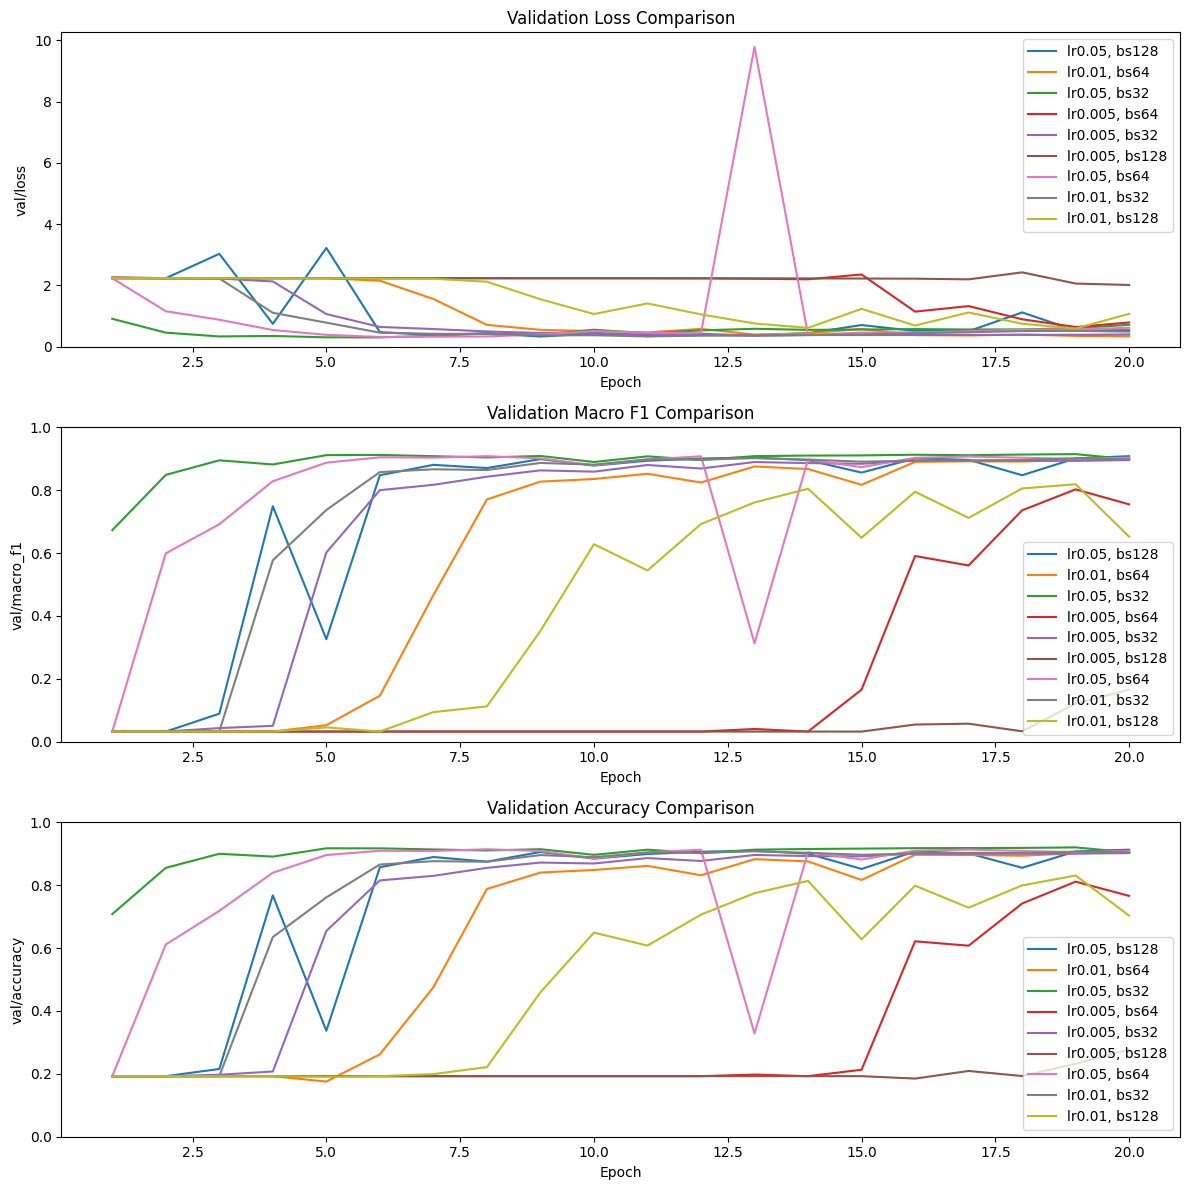

In [ ]:
def plot_comparison(ax, metric_key):
    for run_id	in tuning_result_df["run_id"].unique():
            
        values = tuning_result_df.loc[tuning_result_df["run_id"] == run_id, metric_key]
        epochs = tuning_result_df.loc[tuning_result_df["run_id"] == run_id, "_step"]
        
        # Plot on the specific axis passed to the function
        ax.plot(epochs, values, label=f"{tuning_result_df.loc[tuning_result_df['run_id'] == run_id, 'learning_rate'].iloc[0]}, {tuning_result_df.loc[tuning_result_df['run_id'] == run_id, 'batch_size'].iloc[0]}")

    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric_key)
    ax.legend()

# 2. Create the layout first
fig, axes = plt.subplots(3,1, figsize=(12, 12))

# 3. Pass the specific subplot (axes[0] or axes[1]) to the function
plot_comparison(axes[0], "val/loss")
plot_comparison(axes[1], "val/macro_f1")
plot_comparison(axes[2], "val/accuracy")
axes[0].set_title("Validation Loss Comparison")
axes[1].set_title("Validation Macro F1 Comparison")
axes[2].set_title("Validation Accuracy Comparison")
axes[0].set_ylim(0, None)  # Loss sollte positiv sein
axes[1].set_ylim(0, 1)     # F1-Score liegt zwischen 0 und 1
axes[2].set_ylim(0, 1)     # Accuracy liegt zwischen 0 und 1



plt.tight_layout()
plt.show()

Theorie:
- Zu grosse Lernraten können zu Oszillation oder Divergenz führen (Blaue line am anfang)
- Zu kleine Lernraten konvergieren stabiler, benötigen aber viel mehr Epochen (alle linienen mit tiefer lernrate). Sie könnten in lokalen Minima stecken bleiben.
- Theoretisch: Kleinere Batches erzeugen noisigere Gradienten und können besser generalisieren,  sind rechenintensiver (über doppelt so lange).

Bei 30 Epochen sind die besten Gesamtkonfigurationen eine Lernrate von 0,05 und eine Batchgröße von 128. Damit wurden die höchste Validierungsgenauigkeit (0,913) sowie der stärkste Makro-F1-Wert (0,908) erzielt. Dies deutet darauf hin, dass das Modell nicht nur insgesamt, sondern auch über alle Klassen hinweg relativ ausgewogen gute Ergebnisse liefert.

Ein klares Muster ist, dass größere Batch-Größen nur in Kombination mit einer hohen Lernrate gut funktionieren. So schnitt die Batchgröße 128 bei einer Lernrate von 0,05 am besten ab, bei 0,01 jedoch deutlich schlechter und insbesondere bei 0,005, wo die Leistung stark abfiel. Dies deutet darauf hin, dass die niedrigeren Lernraten bei 30 Epochen weiterhin schwächer waren, insbesondere bei großen Batches.

Bei Batchgrößen von 32 und 64 sind die Ergebnisse stabiler. Die meisten Durchläufe erreichten eine Genauigkeit von etwa 0,90 bzw. 0,89–0,91 bei Makro-Präzision/Recall/F1. Dies deutet darauf hin, dass das Modell in diesem Bereich im Allgemeinen robust ist, obwohl keine dieser Einstellungen die Kombination 0,05/128 übertraf.

Insgesamt deuten die Ergebnisse darauf hin, dass die Konfiguration `0.05/128` unter den hier tatsächlich getesteten 30-Epochen-Runs die beste Wahl ist. Basierend auf diesen Resultaten wird dieses Setup als gemeinsame Baseline für die nachfolgenden Hypothesentests wiederverwendet.


#### 4c) Schätzung des statistischen Fehlers mit Cross-Validation

Die Fold-Splits werden mit `kfold_indices(...)` aus `src.cross_validation` erzeugt.
Trainiert wird pro Fold mit `Trainer` aus `src.training` bei identischem Basismodell und SGD-Setup.

In [ ]:
from src.model import BaselineCNN

X = train_set.data.astype(np.float32)

if X.ndim == 4 and X.shape[1] == 3:
    pass
elif X.ndim == 4 and X.shape[-1] == 3:
    X = X.transpose(0, 3, 1, 2)
else:
    raise ValueError(f"Unexpected SVHN data shape: {X.shape}")

X = X / 255.0
X = (X - mean.numpy()[None, :, None, None]) / std.numpy()[None, :, None, None]
y = train_labels.astype(np.int64)

learning_rate = best_lr if "best_lr" in globals() else 1e-2
batch_size = best_bs if "best_bs" in globals() else 64

net = NeuralNetClassifier(
    BaselineCNN,
    max_epochs=20,
    module__num_classes=10,
    lr=learning_rate,
    batch_size=batch_size,
    optimizer=optim.SGD,
    optimizer__momentum=0.0,
    optimizer__weight_decay=0.0,
    criterion=torch.nn.CrossEntropyLoss,
    device=DEVICE,
    train_split=None,
    verbose=0,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "f1_macro", "precision_macro", "recall_macro"]

results = cross_validate(
    net, X, y, 
    cv=cv, 
    scoring=scoring, 
    n_jobs=-1, 
    return_train_score=True,

)

cv_summary = pd.DataFrame({
    "metric": ["accuracy", "f1_macro", "precision_macro", "recall_macro"],
    "mean": [results[f"test_{m}"].mean() for m in scoring],
    "std": [results[f"test_{m}"].std() for m in scoring],
    "se": [results[f"test_{m}"].std() / np.sqrt(cv.get_n_splits()) for m in scoring],
})

display(cv_summary)


In [ ]:
#Vizualize 

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=cv_summary, x="metric", y="mean", palette="Set2", hue="metric", errorbar=None)

ax.errorbar(
	x=np.arange(len(cv_summary)),
	y=cv_summary["mean"],
	yerr=cv_summary["se"],
	fmt="none",
	ecolor="black",
	capsize=4,
)

plt.title("Cross-Validation Performance")
plt.ylim(0, 1)
plt.show()

## Etappe 2: Hyperparameter Tuning
Im Folgenden sollst Du nun den Trainingsverlauf und die Modellperformance unter Änderung verschiedener Hyperparameter untersuchen. Hierzu sollst Du mind. 10 Hypothesen formulieren, Experimente durchführen, um die Hypothesen zu testen, und die Ergebnisse einordnen und reflektieren.

**Vorgehen pro Hypothese** 

Für jede Hypothese gehst du wie folgt vor:

1. Hypothese: Formuliere deine Erwartung dazu, was sich in der Modellperformance und/oder dem Trainingsverlauf ändert, wenn ein Hyperparameter verändert wird. Begründe diese Hypothese mit Hilfe deines theoretischen Wissens und gib eine entsprechende Referenz an.
2. Experiment: Definiere ein Experiment, mit welchem die Hypothese getestet werden kann und führe es durch.
3. Analyse/Reflexion: Analysiere die Ergebnisse daraufhin, ob sich die Hypothese bestätigt hat, und reflektiere darüber.

**Themengruppen für die Hypothesen**

Die Hypothesen sollen aus folgenden Bereichen gebildet werden:

* Modellkomplexität:
    * Anzahl Conv-Layer und/oder Anzahl linearer Layer (Modelltiefe)
    * Anzahl Filter pro Conv-Layer oder Anzahl Units in linearen Layern (Breite)
   
   Hinweis: Gegebenenfalls muss die Lernrate angepasst werden.
* Settings bei Conv-Layern:
    * Kernel Size
    * Pooling
* Regularisierung:
    * Dropout
    * Data Augmentation
* Verwendung von BatchNorm
* Initialisierung der Gewichte
* Verwendung des Adam Optimizers
* Transfer Learning

In [ ]:
project_path = (
    f"{wandb_runs.entity}/{wandb_runs.project}"
    if wandb_runs.entity
    else wandb_runs.project
)

api = wandb.Api()

baseline_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Baseline_HypTests",
            "config.is_summary_run": False,
        },
    )
)

### Hypothese 1:  Modelltiefe

$H_0: F(M_{\text{deep}}) \leq F(B)$

$H_1: F(M_{\text{deep}}) > F(B)$

Ein moderat tieferes CNN sollte hierarchischere Merkmale lernen und dadurch den Macro-F1 verbessern; erhofft wird insbesondere eine robustere Trennung ähnlich aussehender Ziffern.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Modellarchitektur: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_01.py](../src/hyp_tests/Hypothese_01.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer $M_{\text{deep}}$ wurde das Baseline-Modell in `DeepCNN` kopiert und nur dort minimal angepasst:
- ein zusaetzlicher Convolution-Layer im zweiten Feature-Block (`32 -> 64 -> 128` statt direkt `32 -> 128`),
- identischer Klassifikationskopf wie beim Baseline-Modell,
- identischer Trainings- und Logging-Workflow; im Runner wird nur noch das Deep-Modell ueber dieselben Seeds wie die gespeicherte Baseline trainiert, per W&B geloggt und als Ergebnisdateien exportiert.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp01_results_dir = Path("../src/hyp_tests/results")
hyp01_runs_path = hyp01_results_dir / "hypothesis_01_runs.csv"
baseline_runs_path = hyp01_results_dir / "baseline_runs.csv"
hyp01_summary_path = hyp01_results_dir / "hypothesis_01_summary.json"

if not baseline_runs_path.exists() or not hyp01_runs_path.exists() or not hyp01_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_01.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp01_variant_runs_df = pd.read_csv(hyp01_runs_path)
hyp01_runs_df = pd.concat([baseline_runs_df, hyp01_variant_runs_df], ignore_index=True)
hyp01_metadata = json.loads(hyp01_summary_path.read_text(encoding="utf-8"))
hyp01_test_df = pd.DataFrame([
    build_paired_summary(
        hyp01_runs_df,
        reference_label="baseline",
        variant_label="deep",
        alpha=0.05,
    )
])

hypothese_01_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_01",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp01_wandb_runs = baseline_wandb_runs + hypothese_01_variant_wandb_runs

hyp01_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp01_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp01_history_frames = []
for run in hyp01_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp01_history_frames.append(history)

hyp01_history_df = pd.concat(hyp01_history_frames, ignore_index=True)

display(hyp01_test_df)
display(hyp01_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp01_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'deep'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp01_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'deep'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp01_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'deep']]
    axes[0].plot(['baseline', 'deep'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp01_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 2: Modellbreite

$H_0: F(M_{\text{wide}}) \leq F(B)$

$H_1: F(M_{\text{wide}}) > F(B)$

Mehr Filter bzw. mehr Units sollten die Merkmalsrepräsentation stärken; erwartet wird ein höherer Macro-F1, solange Overfitting durch Regularisierung kontrolliert bleibt. 

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellarchitekturen: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_02.py](../src/hyp_tests/Hypothese_02.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer `M_{\text{wide}}` wurde das Baseline-Modell in `WideCNN` kopiert und nur in der Breite angepasst:
- breitere Convolution-Layer (`3 -> 32 -> 64 -> 256` statt `3 -> 16 -> 32 -> 128`),
- breiterer Klassifikationskopf (`256*8*8 -> 1024 -> 192 -> 10` statt `128*8*8 -> 512 -> 96 -> 10`),
- identischer Trainings- und Logging-Workflow; im Runner wird nur noch das Wide-Modell ueber dieselben Seeds wie die gespeicherte Baseline trainiert, per W&B geloggt und als Ergebnisdateien exportiert.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp02_results_dir = Path("../src/hyp_tests/results")
hyp02_runs_path = hyp02_results_dir / "hypothesis_02_runs.csv"
baseline_runs_path = hyp02_results_dir / "baseline_runs.csv"
hyp02_summary_path = hyp02_results_dir / "hypothesis_02_summary.json"

if not baseline_runs_path.exists() or not hyp02_runs_path.exists() or not hyp02_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_02.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp02_variant_runs_df = pd.read_csv(hyp02_runs_path)
hyp02_runs_df = pd.concat([baseline_runs_df, hyp02_variant_runs_df], ignore_index=True)
hyp02_metadata = json.loads(hyp02_summary_path.read_text(encoding="utf-8"))
hyp02_test_df = pd.DataFrame([
    build_paired_summary(
        hyp02_runs_df,
        reference_label="baseline",
        variant_label="wide",
        alpha=0.05,
    )
])

hypothese_02_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_02",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp02_wandb_runs = baseline_wandb_runs + hypothese_02_variant_wandb_runs

hyp02_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp02_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp02_history_frames = []
for run in hyp02_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp02_history_frames.append(history)

hyp02_history_df = pd.concat(hyp02_history_frames, ignore_index=True)

display(hyp02_test_df)
display(hyp02_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp02_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'wide'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp02_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'wide'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp02_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'wide']]
    axes[0].plot(['baseline', 'wide'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp02_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()



### Hypothese 3: Kernelgrösse

$H_0: F(M_{k=3}) \leq F(B)$

$H_1: F(M_{k=3}) > F(B)$

Kleinere Kernel reduzieren die Parameterzahl und erlauben feinere, gestapelte Merkmalsextraktion; erhofft wird daher ein leicht besserer Macro-F1 bei stabilerem Training.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellarchitekturen: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_03.py](../src/hyp_tests/Hypothese_03.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer `M_{k=3}` wurde das Baseline-Modell in `Kernel3CNN` kopiert und nur bei der Kernelgroesse angepasst:
- alle drei Convolution-Layer verwenden `3x3`-Kernel mit `padding=1` statt `5x5` mit `padding=2`,
- Tiefe, Kanalzahlen, Pooling und Klassifikationskopf bleiben identisch zum Baseline-Modell,
- identischer Trainings- und Logging-Workflow; im Runner wird nur noch das `k=3`-Modell ueber dieselben Seeds wie die gespeicherte Baseline trainiert, per W&B geloggt und als Ergebnisdateien exportiert.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp03_results_dir = Path("../src/hyp_tests/results")
hyp03_runs_path = hyp03_results_dir / "hypothesis_03_runs.csv"
baseline_runs_path = hyp03_results_dir / "baseline_runs.csv"
hyp03_summary_path = hyp03_results_dir / "hypothesis_03_summary.json"

if not baseline_runs_path.exists() or not hyp03_runs_path.exists() or not hyp03_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_03.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp03_variant_runs_df = pd.read_csv(hyp03_runs_path)
hyp03_runs_df = pd.concat([baseline_runs_df, hyp03_variant_runs_df], ignore_index=True)
hyp03_metadata = json.loads(hyp03_summary_path.read_text(encoding="utf-8"))
hyp03_test_df = pd.DataFrame([
    build_paired_summary(
        hyp03_runs_df,
        reference_label="baseline",
        variant_label="k3",
        alpha=0.05,
    )
])


hypothese_03_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_03",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp03_wandb_runs = baseline_wandb_runs + hypothese_03_variant_wandb_runs

hyp03_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp03_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp03_history_frames = []
for run in hyp03_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp03_history_frames.append(history)

hyp03_history_df = pd.concat(hyp03_history_frames, ignore_index=True)

display(hyp03_test_df)
display(hyp03_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp03_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'k3'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp03_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'k3'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp03_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'k3']]
    axes[0].plot(['baseline', 'k3'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp03_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 4: Poolingverhalten

$H_0: F(M_{\text{pool-late}}) \leq F(B)$

$H_1: F(M_{\text{pool-late}}) > F(B)$

Da SVHN kleine natürliche Bildausschnitte mit teils feinen Zifferndetails enthält, könnte späteres oder reduziertes Pooling mehr relevante Information erhalten; erhofft wird ein besserer Macro-F1.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellarchitekturen: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_04.py](../src/hyp_tests/Hypothese_04.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer `M_{\text{pool-late}}` wurde das Baseline-Modell in `PoolLateCNN` kopiert und nur beim Pooling angepasst:
- die erste Pooling-Stufe nach dem zweiten Convolution-Layer entfällt,
- es bleibt nur ein spaeteres MaxPooling nach dem dritten Convolution-Layer erhalten,
- der erste Linear-Layer wird nur wegen der groesseren Feature-Map von `128*8*8` auf `128*16*16` angepasst; die restliche Klassifikationsstruktur bleibt gleich,
- identischer Trainings- und Logging-Workflow; im Runner wird nur noch das `pool-late`-Modell ueber dieselben Seeds wie die gespeicherte Baseline trainiert, per W&B geloggt und als Ergebnisdateien exportiert.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp04_results_dir = Path("../src/hyp_tests/results")
hyp04_runs_path = hyp04_results_dir / "hypothesis_04_runs.csv"
baseline_runs_path = hyp04_results_dir / "baseline_runs.csv"
hyp04_summary_path = hyp04_results_dir / "hypothesis_04_summary.json"

if not baseline_runs_path.exists() or not hyp04_runs_path.exists() or not hyp04_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_04.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp04_variant_runs_df = pd.read_csv(hyp04_runs_path)
hyp04_runs_df = pd.concat([baseline_runs_df, hyp04_variant_runs_df], ignore_index=True)
hyp04_metadata = json.loads(hyp04_summary_path.read_text(encoding="utf-8"))
hyp04_test_df = pd.DataFrame([
    build_paired_summary(
        hyp04_runs_df,
        reference_label="baseline",
        variant_label="pool-late",
        alpha=0.05,
    )
])

hypothese_04_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_04",
            "config.is_summary_run": False,
        },
    )
)
if not hypothese_04_variant_wandb_runs:
    raise ValueError("Keine W&B-Runs fuer Hypothese 4 gefunden. Bitte danach src/hyp_tests/Hypothese_04.py ausfuehren.")


In [ ]:
hyp04_wandb_runs = baseline_wandb_runs + hypothese_04_variant_wandb_runs

hyp04_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp04_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp04_history_frames = []
for run in hyp04_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp04_history_frames.append(history)

hyp04_history_df = pd.concat(hyp04_history_frames, ignore_index=True)

display(hyp04_test_df)
display(hyp04_wandb_final_df)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp04_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'pool-late'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp04_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'pool-late'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp04_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'pool-late']]
    axes[0].plot(['baseline', 'pool-late'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp04_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 5: Dropout
$H_0: F(M_{\text{drop}=0.3}) \leq F(B)$

$H_1: F(M_{\text{drop}=0.3}) > F(B)$

Moderates Dropout sollte Co-Adaptation reduzieren und Overfitting im Klassifikationskopf dämpfen; erwartet wird vor allem eine bessere Generalisierung auf dem Testset.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellarchitekturen: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_05.py](../src/hyp_tests/Hypothese_05.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer `M_{\text{drop}=0.3}` wurde das Baseline-Modell in `DropoutCNN` kopiert und nur im Klassifikationskopf angepasst:
- nach jeder ReLU-Aktivierung der beiden Hidden-Layer im Classifier wurde `Dropout(p=0.3)` eingefuegt,
- Convolution-Teil, Layerbreiten und Pooling bleiben identisch zum Baseline-Modell,
- identischer Trainings- und Logging-Workflow; im Runner wird nur noch das `dropout-0.3`-Modell ueber dieselben Seeds wie die gespeicherte Baseline trainiert, per W&B geloggt und als Ergebnisdateien exportiert.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp05_results_dir = Path("../src/hyp_tests/results")
hyp05_runs_path = hyp05_results_dir / "hypothesis_05_runs.csv"
baseline_runs_path = hyp05_results_dir / "baseline_runs.csv"
hyp05_summary_path = hyp05_results_dir / "hypothesis_05_summary.json"

if not baseline_runs_path.exists() or not hyp05_runs_path.exists() or not hyp05_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_05.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp05_variant_runs_df = pd.read_csv(hyp05_runs_path)
hyp05_runs_df = pd.concat([baseline_runs_df, hyp05_variant_runs_df], ignore_index=True)
hyp05_metadata = json.loads(hyp05_summary_path.read_text(encoding="utf-8"))
hyp05_test_df = pd.DataFrame([
    build_paired_summary(
        hyp05_runs_df,
        reference_label="baseline",
        variant_label="dropout-0.3",
        alpha=0.05,
    )
])

hypothese_05_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_05",
            "config.is_summary_run": False,
        },
    )
)
if not hypothese_05_variant_wandb_runs:
    raise ValueError("Keine W&B-Runs fuer Hypothese 5 gefunden. Bitte danach src/hyp_tests/Hypothese_05.py ausfuehren.")


In [ ]:
hyp05_wandb_runs = baseline_wandb_runs + hypothese_05_variant_wandb_runs

hyp05_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp05_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp05_history_frames = []
for run in hyp05_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp05_history_frames.append(history)

hyp05_history_df = pd.concat(hyp05_history_frames, ignore_index=True)

display(hyp05_test_df)
display(hyp05_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp05_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'dropout-0.3'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp05_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'dropout-0.3'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp05_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'dropout-0.3']]
    axes[0].plot(['baseline', 'dropout-0.3'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp05_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 6: Data Augmentation

$H_0: F(M_{\text{aug}}) \leq F(B)$

$H_1: F(M_{\text{aug}}) > F(B)$

Leichte Augmentationen wie kleine Translationen, Rotationen oder Helligkeitsänderungen sollten die Varianz der Trainingsdaten erhöhen; erhofft wird ein höherer Macro-F1 und ein geringerer Generalisierungsfehler.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Trainingslogik mit optionalem `val_loader`: [src/training.py](../src/training.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_06.py](../src/hyp_tests/Hypothese_06.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer `M_{\text{aug}}` bleibt die Modellarchitektur identisch zum Baseline-Modell; veraendert wird nur die Dateneingabe im Training:
- auf dem Trainingssplit werden leichte Augmentationen angewendet: `RandomAffine(degrees=8, translate=(0.08, 0.08))` und `ColorJitter(brightness=0.15, contrast=0.10)`,
- der Validierungssplit bleibt bewusst ohne Augmentation und wird nur normalisiert,
- dafuer wurde `run_model(...)` minimal erweitert, sodass optional ein separater `val_loader` uebergeben werden kann; damit bleiben Trainings- und Validierungs-Transformationen sauber getrennt.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp06_results_dir = Path("../src/hyp_tests/results")
hyp06_runs_path = hyp06_results_dir / "hypothesis_06_runs.csv"
baseline_runs_path = hyp06_results_dir / "baseline_runs.csv"
hyp06_summary_path = hyp06_results_dir / "hypothesis_06_summary.json"

if not baseline_runs_path.exists() or not hyp06_runs_path.exists() or not hyp06_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_06.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp06_variant_runs_df = pd.read_csv(hyp06_runs_path)
hyp06_runs_df = pd.concat([baseline_runs_df, hyp06_variant_runs_df], ignore_index=True)
hyp06_metadata = json.loads(hyp06_summary_path.read_text(encoding="utf-8"))
hyp06_test_df = pd.DataFrame([
    build_paired_summary(
        hyp06_runs_df,
        reference_label="baseline",
        variant_label="aug",
        alpha=0.05,
    )
])

hypothese_06_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_06",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp06_wandb_runs = baseline_wandb_runs + hypothese_06_variant_wandb_runs

hyp06_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp06_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp06_history_frames = []
for run in hyp06_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp06_history_frames.append(history)

hyp06_history_df = pd.concat(hyp06_history_frames, ignore_index=True)

display(hyp06_test_df)
display(hyp06_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp06_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'aug'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp06_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'aug'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp06_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'aug']]
    axes[0].plot(['baseline', 'aug'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp06_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 7: Batch Normalization

$H_0: F(M_{\text{BN}}) \leq F(B)$

$H_1: F(M_{\text{BN}}) > F(B)$

BatchNorm sollte die Optimierung erleichtern und die Konvergenz beschleunigen; erwartet wird ein glatterer Trainingsverlauf und mindestens ein leicht besserer Macro-F1.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellvarianten: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_07.py](../src/hyp_tests/Hypothese_07.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer `M_{\text{BN}}` bleibt die Grundarchitektur des Baseline-Modells unveraendert; ergaenzt werden nur `BatchNorm2d`-Schichten direkt nach den drei Convolution-Layern. Damit aendert sich gegenueber der Baseline nur das Normalisierungsverhalten innerhalb des CNN-Feature-Extractors, waehrend Tiefe, Breite, Kernelgroessen, Pooling und Klassifikationskopf gleich bleiben.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp07_results_dir = Path("../src/hyp_tests/results")
hyp07_runs_path = hyp07_results_dir / "hypothesis_07_runs.csv"
baseline_runs_path = hyp07_results_dir / "baseline_runs.csv"
hyp07_summary_path = hyp07_results_dir / "hypothesis_07_summary.json"

if not baseline_runs_path.exists() or not hyp07_runs_path.exists() or not hyp07_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_07.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp07_variant_runs_df = pd.read_csv(hyp07_runs_path)
hyp07_runs_df = pd.concat([baseline_runs_df, hyp07_variant_runs_df], ignore_index=True)
hyp07_metadata = json.loads(hyp07_summary_path.read_text(encoding="utf-8"))
hyp07_test_df = pd.DataFrame([
    build_paired_summary(
        hyp07_runs_df,
        reference_label="baseline",
        variant_label="batchnorm",
        alpha=0.05,
    )
])

hypothese_07_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_07",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp07_wandb_runs = baseline_wandb_runs + hypothese_07_variant_wandb_runs

hyp07_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp07_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp07_history_frames = []
for run in hyp07_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp07_history_frames.append(history)

hyp07_history_df = pd.concat(hyp07_history_frames, ignore_index=True)

display(hyp07_test_df)
display(hyp07_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp07_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'batchnorm'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp07_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'batchnorm'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp07_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'batchnorm']]
    axes[0].plot(['baseline', 'batchnorm'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp07_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 8: Initialisierungsfunktion

$H_0: F(M_{\text{He}}) \leq F(M_{\text{Xav}})$

$H_1: F(M_{\text{He}}) > F(M_{\text{Xav}})$

Da das Modell ReLU-Aktivierungen verwendet, sollte He-Initialisierung die Gradienten besser skalieren als Xavier; erhofft wird ein stabilerer Start und bessere Endleistung.

**Implementierung**

- Gemeinsame Baseline-Konfiguration: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellvarianten: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_08.py](../src/hyp_tests/Hypothese_08.py)

Die gespeicherte Baseline wird hier nicht als Vergleichsmodell verwendet, sondern nur als Quelle fuer die beste Tuning-Konfiguration aus dem Notebook (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) sowie fuer die festen Repeat-Seeds.

Verglichen werden zwei ansonsten identische Baseline-Modelle:
- `M_{\text{Xav}}`: Baseline-Architektur mit `Xavier`-Initialisierung aller Convolution- und Linear-Layer,
- `M_{\text{He}}`: dieselbe Architektur mit `He`-Initialisierung derselben Layer.

Damit unterscheidet sich zwischen beiden Modellen ausschliesslich die Initialisierungsfunktion; Architektur, Daten, Trainingseinstellungen und Auswertung bleiben gleich.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp08_results_dir = Path("../src/hyp_tests/results")
hyp08_runs_path = hyp08_results_dir / "hypothesis_08_runs.csv"
hyp08_summary_path = hyp08_results_dir / "hypothesis_08_summary.json"

if not hyp08_runs_path.exists() or not hyp08_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Hypothese_08.py ausfuehren, damit die Ergebnisdateien erzeugt werden.")

hyp08_runs_df = pd.read_csv(hyp08_runs_path)
hyp08_metadata = json.loads(hyp08_summary_path.read_text(encoding="utf-8"))
hyp08_test_df = pd.DataFrame([
    build_paired_summary(
        hyp08_runs_df,
        reference_label="xavier",
        variant_label="he",
        alpha=0.05,
    )
])

project_path = (
    f"{wandb_runs.entity}/{wandb_runs.project}"
    if wandb_runs.entity
    else wandb_runs.project
)
api = wandb.Api()
hyp08_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_08",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp08_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp08_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp08_history_frames = []
for run in hyp08_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp08_history_frames.append(history)

hyp08_history_df = pd.concat(hyp08_history_frames, ignore_index=True)

display(hyp08_test_df)
display(hyp08_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp08_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['xavier', 'he'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp08_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['xavier', 'he'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp08_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['xavier', 'he']]
    axes[0].plot(['xavier', 'he'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp08_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 9: Optimizer

$H_0: F(M_{\text{Adam}}) \leq F(M_{\text{SGD}})$

$H_1: F(M_{\text{Adam}}) > F(M_{\text{SGD}})$

Adam passt die Lernrate parameterweise an und ist oft bei verrauschten Gradienten effizient; erwartet wird ein schnellerer Lernfortschritt und ein mindestens leicht höherer Macro-F1. 

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Trainingslogik mit optionaler Optimizer-Factory: [src/training.py](../src/training.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_09.py](../src/hyp_tests/Hypothese_09.py)

Die gemeinsame Baseline dient hier direkt als Referenzmodell `M_{\text{SGD}}`, da sie bereits mit `SGD` trainiert wird und mit der besten Tuning-Konfiguration aus dem Notebook gespeichert ist (`learning_rate=0.05`, `batch_size=128`, `epochs=30`).

Fuer `M_{\text{Adam}}` bleibt das Modell identisch zum Baseline-CNN; veraendert wird ausschliesslich der Optimizer von `SGD` auf `Adam`. Dafuer wurde `run_model(...)` minimal erweitert, sodass optional eine andere Optimizer-Factory uebergeben werden kann, waehrend das bisherige Standardverhalten unveraendert `SGD` bleibt.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp09_results_dir = Path("../src/hyp_tests/results")
hyp09_runs_path = hyp09_results_dir / "hypothesis_09_runs.csv"
baseline_runs_path = hyp09_results_dir / "baseline_runs.csv"
hyp09_summary_path = hyp09_results_dir / "hypothesis_09_summary.json"

if not baseline_runs_path.exists() or not hyp09_runs_path.exists() or not hyp09_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_09.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp09_variant_runs_df = pd.read_csv(hyp09_runs_path)
hyp09_runs_df = pd.concat([baseline_runs_df, hyp09_variant_runs_df], ignore_index=True)
hyp09_metadata = json.loads(hyp09_summary_path.read_text(encoding="utf-8"))
hyp09_test_df = pd.DataFrame([
    build_paired_summary(
        hyp09_runs_df,
        reference_label="baseline",
        variant_label="adam",
        alpha=0.05,
    )
])


hypothese_09_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_09",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp09_wandb_runs = baseline_wandb_runs + hypothese_09_variant_wandb_runs

hyp09_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp09_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp09_history_frames = []
for run in hyp09_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp09_history_frames.append(history)

hyp09_history_df = pd.concat(hyp09_history_frames, ignore_index=True)

display(hyp09_test_df)
display(hyp09_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp09_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'adam'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp09_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'adam'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp09_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'adam']]
    axes[0].plot(['baseline', 'adam'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp09_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


### Hypothese 10: Transfer Learning 

$H_0: F(M_{\text{TL}}) \leq F(B)$

$H_1: F(M_{\text{TL}}) > F(B)$

Ein vortrainiertes Modell sollte bereits nützliche visuelle Grundmerkmale enthalten; erhofft wird deshalb eine schnellere Konvergenz und eine bessere Testleistung als beim reinen Training von Grund auf.

**Implementierung**

- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Gemeinsame Hilfsfunktionen: [src/hyp_tests/common.py](../src/hyp_tests/common.py)
- Modellvarianten: [src/model.py](../src/model.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_10.py](../src/hyp_tests/Hypothese_10.py)

Die gemeinsame Baseline wird wiederverwendet und mit derselben besten Tuning-Konfiguration aus dem Notebook verglichen (`learning_rate=0.05`, `batch_size=128`, `epochs=30`).

Fuer `M_{\text{TL}}` wird das Baseline-CNN durch ein vortrainiertes `ResNet18` ersetzt:
- das Backbone startet mit ImageNet-Gewichten,
- nur der finale Klassifikationskopf wird fuer die 10 SVHN-Klassen neu trainiert,
- die Eingabebilder werden auf `224 x 224` skaliert und mit den ImageNet-Normalisierungswerten normalisiert.

Damit aendert sich gegenueber der Baseline gezielt der Modellstartpunkt durch Vortraining; zusaetzlich wird die Dateneingabe an das vortrainierte Backbone angepasst.

Die Runner fuehren selbst keinen Hypothesentest mehr aus, sondern speichern nur die Trainingsruns und Ergebnisdateien. Der eigentliche einseitige gepaarte t-Test auf `test_macro_f1` wird in der Notebook-Zelle darunter als Tabelle aus diesen exportierten Daten berechnet.


In [ ]:
hyp10_results_dir = Path("../src/hyp_tests/results")
hyp10_runs_path = hyp10_results_dir / "hypothesis_10_runs.csv"
baseline_runs_path = hyp10_results_dir / "baseline_runs.csv"
hyp10_summary_path = hyp10_results_dir / "hypothesis_10_summary.json"

if not baseline_runs_path.exists() or not hyp10_runs_path.exists() or not hyp10_summary_path.exists():
    raise FileNotFoundError("Bitte zuerst src/hyp_tests/Baseline.py und src/hyp_tests/Hypothese_10.py ausfuehren, damit beide Ergebnisdateien fuer den Vergleich vorliegen.")

baseline_runs_df = pd.read_csv(baseline_runs_path)
hyp10_variant_runs_df = pd.read_csv(hyp10_runs_path)
hyp10_runs_df = pd.concat([baseline_runs_df, hyp10_variant_runs_df], ignore_index=True)
hyp10_metadata = json.loads(hyp10_summary_path.read_text(encoding="utf-8"))
hyp10_test_df = pd.DataFrame([
    build_paired_summary(
        hyp10_runs_df,
        reference_label="baseline",
        variant_label="transfer-learning",
        alpha=0.05,
    )
])


hypothese_10_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_10",
            "config.is_summary_run": False,
        },
    )
)

In [ ]:
hyp10_wandb_runs = baseline_wandb_runs + hypothese_10_variant_wandb_runs

hyp10_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp10_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp10_history_frames = []
for run in hyp10_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    if history.empty:
        continue
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp10_history_frames.append(history)

hyp10_history_df = pd.concat(hyp10_history_frames, ignore_index=True)

display(hyp10_test_df)
display(hyp10_wandb_final_df)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp10_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'transfer-learning'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp10_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'transfer-learning'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
for repeat_idx, repeat_df in hyp10_runs_df.groupby("repeat_idx"):
    ordered = repeat_df.set_index("model_variant").loc[['baseline', 'transfer-learning']]
    axes[0].plot(['baseline', 'transfer-learning'], ordered["test_macro_f1"], color="gray", alpha=0.35)
axes[0].set_title("Finaler Validation Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp10_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="sd",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()
